# Notebook 02 — Preprocesamiento

**Maestría en Data Mining · FCEyN UBA · Taller de Tesis I · Grupo G2**

Aplica el pipeline completo de limpieza, imputación, encoding ordinal, binarización multi-valor
y OHE para generar **dos artefactos parquet**:

1. `data/df_clean.parquet` — dataset **full** (sin restricción de población, 155k filas).
2. `data/df_clean_users.parquet` — dataset **restringido a usuarios activos** (`AISelect=Yes`, ~80k filas).

**Lógica:** importada de `scripts/pipeline.py`. Este notebook orquesta y reporta.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import importlib.util
spec = importlib.util.spec_from_file_location("pipeline", ROOT / "scripts" / "pipeline.py")
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"TARGET_LABELS = {pipeline.TARGET_LABELS}")
print(f"DEVTYPE_2025_REMAP = {pipeline.DEVTYPE_2025_REMAP}")

TARGET_LABELS = {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}
DEVTYPE_2025_REMAP = {'AI/ML engineer': 'Data scientist or machine learning specialist', 'Data engineer': 'Data scientist or machine learning specialist'}


## 2. Construir dataset FULL (sin restricción)

Llamamos `pipeline.construir_dataset(restrict_to_users=False, save=True)`. Esto:
1. Carga los 3 CSV crudos.
2. Aplica normalizaciones de schema (AISelect 2025, AIBen↔AIAcc swap 2023, DevType 2025 remap).
3. Construye target binario.
4. Filtra a `MainBranch == 'I am a developer by profession'` (155k filas).
5. Aplica imputación, encoding ordinal, binarización, OHE.
6. Persiste en `data/df_clean.parquet`.

In [2]:
df_full = pipeline.construir_dataset(restrict_to_users=False, save=True)
print(f"\nShape final: {df_full.shape}")
print(f"Nulos residuales: {df_full.isnull().sum().sum()}")

Cargados: 2023=89,184  2024=65,437  2025=49,191
DevType 2025 recodificado: 1447 respondientes en DS/ML (unión nueva)
✅ Schemas normalizados


Tras filtro MainBranch: 154,911 (de 203,812)

=== Distribución del target ===
Total: 154,911 filas
Target=1 (Sin discrepancia): 63,074 (40.7%)
Target=0 (Con discrepancia uso-actitud): 91,837 (59.3%)

Por año:
             count    sum   mean
survey_year                     
2023         67237  25144  0.374
2024         50207  22695  0.452
2025         37467  15235  0.407
Tras Sección 2: (154911, 18)
Descartadas por >40.0% nulos: ['JobSat', 'Industry']
Tras imputación: 52601 nulos residuales



✅ Guardado: /home/daro-m/Personal/maestria-taller-de-tesis-1/data/df_clean.parquet  (2.5 MB, 154,911 × 101 cols)

Shape final: (154911, 101)
Nulos residuales: 0


## 3. Construir dataset USUARIOS (restringido)

Mismo pipeline pero con `restrict_to_users=True` → filtra a `AISelect=Yes`.

In [3]:
df_users = pipeline.construir_dataset(restrict_to_users=True, save=True)
print(f"\nShape final: {df_users.shape}")
print(f"Nulos residuales: {df_users.isnull().sum().sum()}")

Cargados: 2023=89,184  2024=65,437  2025=49,191
DevType 2025 recodificado: 1447 respondientes en DS/ML (unión nueva)
✅ Schemas normalizados


Tras filtro MainBranch: 154,911 (de 203,812)


Tras filtro AISelect=Yes (usuarios activos): 80,369 (de 154,911)

=== Distribución del target ===
Total: 80,369 filas
Target=1 (Sin discrepancia): 63,074 (78.5%)
Target=0 (Con discrepancia uso-actitud): 17,295 (21.5%)

Por año:
             count    sum   mean
survey_year                     
2023         29697  25144  0.847
2024         29638  22695  0.766
2025         21034  15235  0.724
Tras Sección 2: (80369, 18)
Descartadas por >40.0% nulos: ['JobSat']
Tras imputación: 20024 nulos residuales



✅ Guardado: /home/daro-m/Personal/maestria-taller-de-tesis-1/data/df_clean_users.parquet  (1.5 MB, 80,369 × 124 cols)

Shape final: (80369, 124)
Nulos residuales: 0


## 4. Comparativa de los dos datasets

In [4]:
comparativa = pd.DataFrame({
    "Métrica": [
        "N filas",
        "N columnas",
        "Tamaño (MB)",
        "Target = 1 (Sin discrepancia)",
        "Target = 0 (Con discrepancia uso-actitud)",
        "Tasa target = 1 (%)",
    ],
    "Full (df_clean.parquet)": [
        f"{len(df_full):,}",
        df_full.shape[1],
        f"{(pipeline.output_path(False).stat().st_size / 1024**2):.1f}",
        f"{df_full['target'].sum():,}",
        f"{(1-df_full['target']).sum():,}",
        f"{df_full['target'].mean() * 100:.1f}",
    ],
    "Usuarios (df_clean_users.parquet)": [
        f"{len(df_users):,}",
        df_users.shape[1],
        f"{(pipeline.output_path(True).stat().st_size / 1024**2):.1f}",
        f"{df_users['target'].sum():,}",
        f"{(1-df_users['target']).sum():,}",
        f"{df_users['target'].mean() * 100:.1f}",
    ],
})
comparativa

,Métrica,Full (df_clean.parquet),Usuarios (df_clean_users.parquet)
0,N filas,"154,911","80,369"
1,N columnas,101,124
2,Tamaño (MB),2.5,1.5
3,Target = 1 (Sin discrepancia),"63,074","63,074"
4,Target = 0 (Con discrepancia uso-actitud),"91,837","17,295"
5,Tasa target = 1 (%),40.7,78.5


**Lectura.** Al restringir a usuarios:
- N cae de 155k a ~80k (~50% menos).
- **Distribución target se invierte:** pasa de 41/59 (full) a 78,5/21,5 (users).
- Target = 0 (con discrepancia) pasa de ser mayoritaria a minoritaria.
- Esto refleja que al filtrar a `AISelect=Yes`, eliminamos a los no-usuarios — todos los cuales tenían `target=0` automáticamente.

## 5. Distribución del target por año

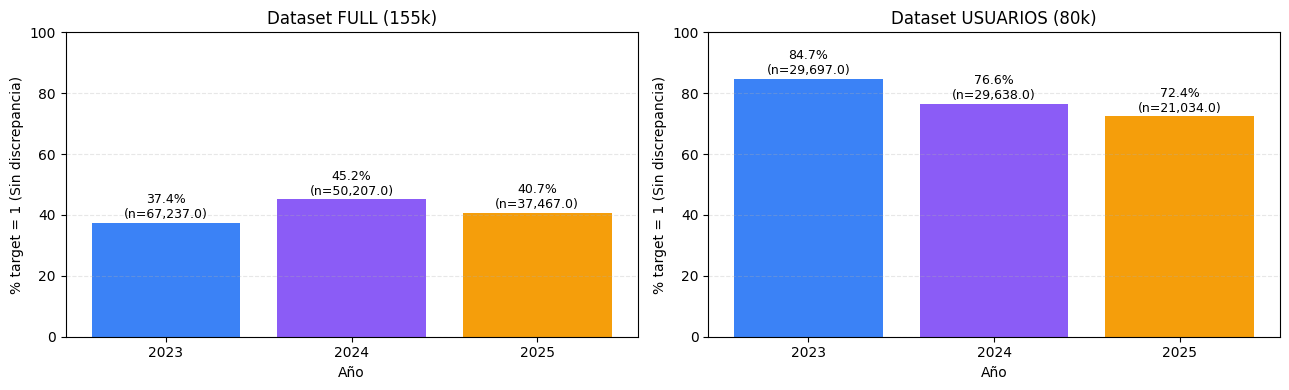

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, df, title in [(axes[0], df_full, "Dataset FULL (155k)"),
                       (axes[1], df_users, "Dataset USUARIOS (80k)")]:
    dist = df.groupby("survey_year")["target"].agg(["count", "mean"])
    dist["mean_pct"] = dist["mean"] * 100
    ax.bar(dist.index.astype(str), dist["mean_pct"], color=["#3b82f6", "#8b5cf6", "#f59e0b"])
    ax.set_ylabel("% target = 1 (Sin discrepancia)")
    ax.set_xlabel("Año")
    ax.set_title(title)
    ax.set_ylim(0, 100)
    for i, (_, row) in enumerate(dist.iterrows()):
        ax.text(i, row["mean_pct"] + 1.5, f"{row['mean_pct']:.1f}%\n(n={row['count']:,})",
                ha="center", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Observación.** En el dataset FULL la tasa de target=1 sube de 37 % (2023) a 45 % (2024) y baja a 41 % (2025). En el dataset USUARIOS arranca alta (85 % en 2023) y cae a 72 % en 2025 — la discrepancia (target=0) crece entre usuarios año a año.

## 6. Features finales — inventario por familia

Categorizamos las 124 columnas finales por familia para entender la estructura del dataset.

Distribución de features por familia:
Industria           23
Lenguaje            21
Plataforma          16
Entorno dev         16
DevType             12
Base de datos       11
Trabajo remoto       6
Región               6
Numérica/Ordinal     5
Modalidad empleo     4
Rol IC/PM            2
Temporal             1
Target               1


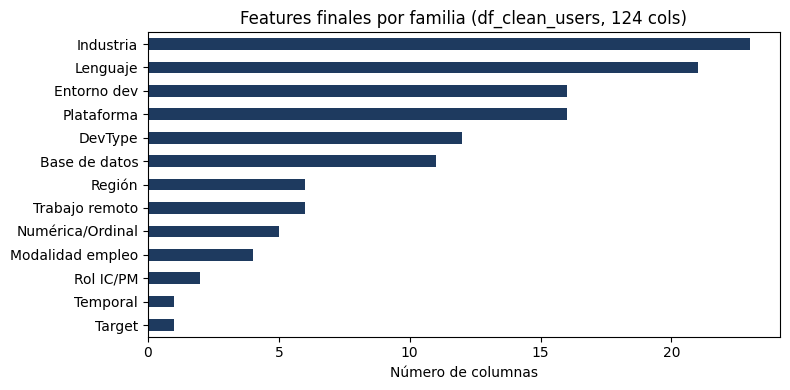

In [6]:
def familia(col):
    if col == "target":
        return "Target"
    if col == "survey_year":
        return "Temporal"
    if col.startswith("lang_"):
        return "Lenguaje"
    if col.startswith("db_"):
        return "Base de datos"
    if col.startswith("plat_"):
        return "Plataforma"
    if col.startswith("env_"):
        return "Entorno dev"
    if col.startswith("Employment_"):
        return "Modalidad empleo"
    if col.startswith("RemoteWork_"):
        return "Trabajo remoto"
    if col.startswith("ICorPM_"):
        return "Rol IC/PM"
    if col.startswith("Region_"):
        return "Región"
    if col.startswith("DevType_"):
        return "DevType"
    if col.startswith("Industry_"):
        return "Industria"
    if col.endswith("_count"):
        return "Count agregado"
    return "Numérica/Ordinal"

fam = pd.Series([familia(c) for c in df_users.columns]).value_counts()
print("Distribución de features por familia:")
print(fam.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
fam.sort_values().plot(kind="barh", ax=ax, color="#1E3A5F")
ax.set_xlabel("Número de columnas")
ax.set_title("Features finales por familia (df_clean_users, 124 cols)")
plt.tight_layout()
plt.show()

## 7. Próximo paso

- `notebooks/03_eda.ipynb` — Análisis exploratorio: H1, H2, H4 sobre ambos datasets + H5 (full) + invarianza estratificada.
- `notebooks/04_modelado.ipynb` — Modelado supervisado y SHAP sobre dataset usuarios.